# ESM2 Training

In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pathlib import Path
import json

RANDOM=42
DATA = Path("outputs")

In [12]:
dfs = []

for dir in DATA.iterdir():
  model, mode = dir.name.split('_')

  df = pd.read_csv(dir / "history.csv")
  cols = df.columns
  df['model'] = model
  df['mode'] = mode
  df = df[['model', 'mode'] + [c for c in cols]]
  dfs.append(df)

df = pd.concat(dfs, ignore_index=True)
df.head()

,model,mode,epoch,seconds,peak_gpu_memory_gb,train_macro_f1,train_micro_f1,train_exact_match,train_loss,val_macro_f1,val_micro_f1,val_exact_match,val_loss
0,esm150m,frozen,1,329.063985,0.72568,0.406841,0.492165,0.130607,0.938654,0.422113,0.505347,0.149396,0.792122
1,esm150m,frozen,2,327.704450,0.72568,0.439604,0.530150,0.164908,0.838061,0.440468,0.537525,0.202373,0.744498
2,esm150m,frozen,3,328.086278,0.72568,0.449082,0.541710,0.180536,0.805058,0.444450,0.547711,0.181394,0.726210
3,esm150m,frozen,4,328.051509,0.72568,0.456491,0.550077,0.189162,0.786343,0.435710,0.529415,0.198771,0.718881
4,esm150m,frozen,5,328.329654,0.72568,0.460463,0.555477,0.197889,0.772835,0.451836,0.546600,0.207671,0.706808


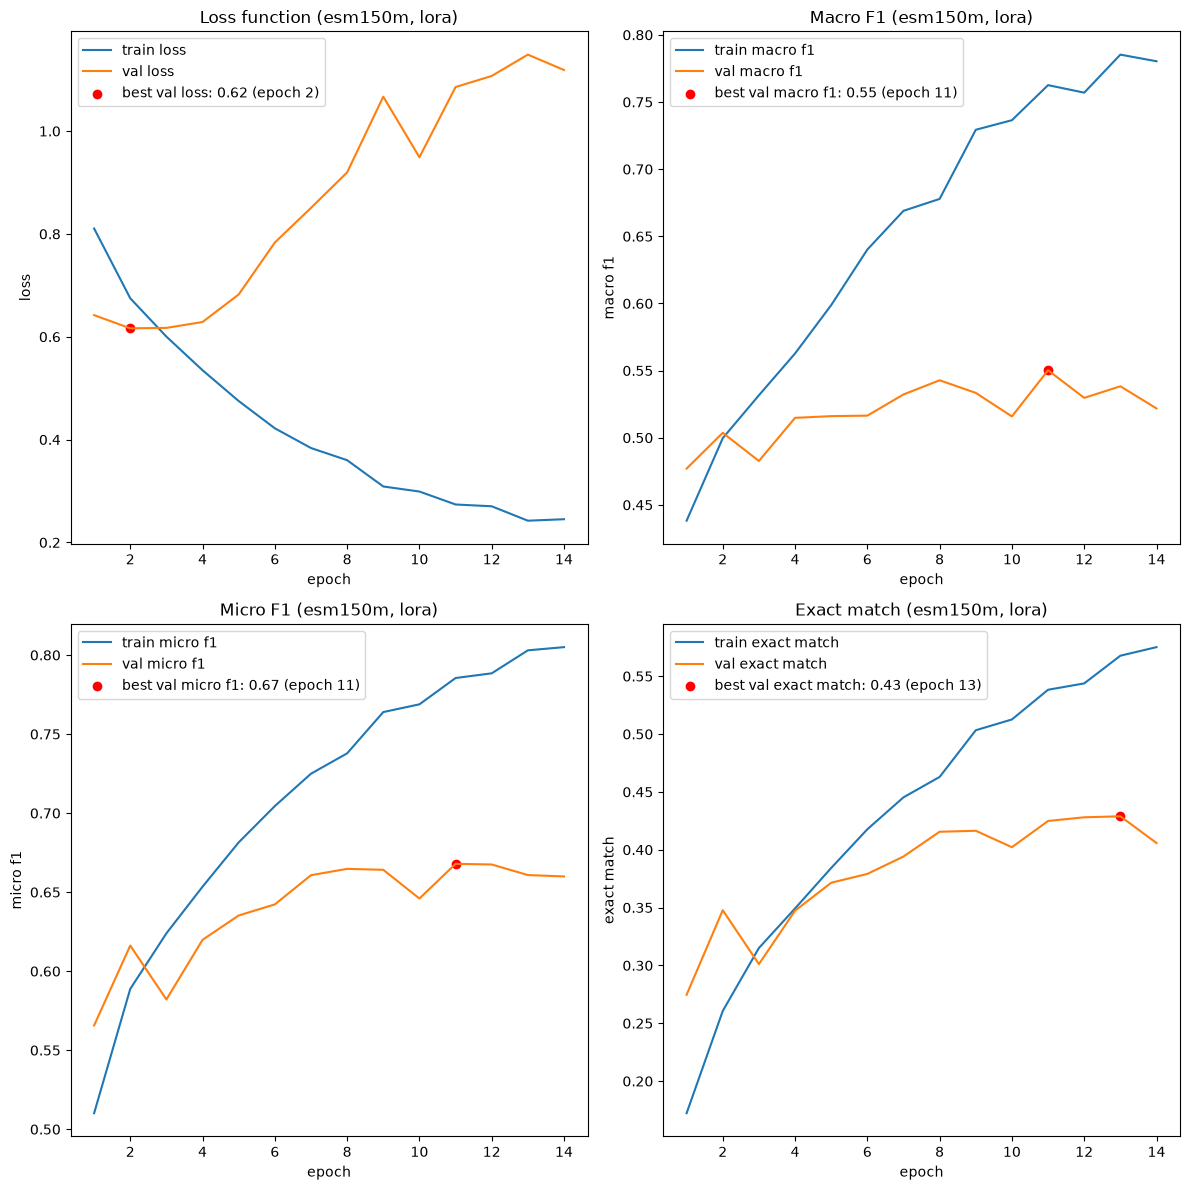

In [31]:
model = 'esm150m'
mode = 'lora'

data = df[df['model'].eq(model) & df['mode'].eq(mode)]

fig, ax = plt.subplots(2, 2, figsize=(12, 12))

best = data.loc[data['val_loss'].idxmin()]
best_epoch, best_loss = best['epoch'], best['val_loss']

ax[0][0].plot(data['epoch'], data['train_loss'], label='train loss')
ax[0][0].plot(data['epoch'], data['val_loss'], label='val loss')
ax[0][0].scatter(
  best_epoch, best_loss,
  color='red',
  label=f'best val loss: {best_loss:.2f} (epoch {best_epoch})'
)

ax[0][0].set_title(f'Loss function ({model}, {mode})')
ax[0][0].set_ylabel('loss')
ax[0][0].set_xlabel('epoch')
ax[0][0].legend()

best = data.loc[data['val_macro_f1'].idxmax()]
best_epoch, best_macro_f1 = best['epoch'], best['val_macro_f1']

ax[0][1].plot(data['epoch'], data['train_macro_f1'], label='train macro f1')
ax[0][1].plot(data['epoch'], data['val_macro_f1'], label='val macro f1')
ax[0][1].scatter(
  best_epoch, best_macro_f1,
  color='red',
  label=f'best val macro f1: {best_macro_f1:.2f} (epoch {best_epoch})'
)

ax[0][1].set_title(f'Macro F1 ({model}, {mode})')
ax[0][1].set_ylabel('macro f1')
ax[0][1].set_xlabel('epoch')
ax[0][1].legend()

best = data.loc[data['val_micro_f1'].idxmax()]
best_epoch, best_micro_f1 = best['epoch'], best['val_micro_f1']

ax[1][0].plot(data['epoch'], data['train_micro_f1'], label='train micro f1')
ax[1][0].plot(data['epoch'], data['val_micro_f1'], label='val micro f1')
ax[1][0].scatter(
  best_epoch, best_micro_f1,
  color='red',
  label=f'best val micro f1: {best_micro_f1:.2f} (epoch {best_epoch})'
)

ax[1][0].set_title(f'Micro F1 ({model}, {mode})')
ax[1][0].set_ylabel('micro f1')
ax[1][0].set_xlabel('epoch')
ax[1][0].legend()

best = data.loc[data['val_exact_match'].idxmax()]
best_epoch, best_exact_match = best['epoch'], best['val_exact_match']

ax[1][1].plot(data['epoch'], data['train_exact_match'], label='train exact match')
ax[1][1].plot(data['epoch'], data['val_exact_match'], label='val exact match')
ax[1][1].scatter(
  best_epoch, best_exact_match,
  color='red',
  label=f'best val exact match: {best_exact_match:.2f} (epoch {best_epoch})'
)

ax[1][1].set_title(f'Exact match ({model}, {mode})')
ax[1][1].set_ylabel('exact match')
ax[1][1].set_xlabel('epoch')
ax[1][1].legend()

fig.tight_layout()
plt.show()

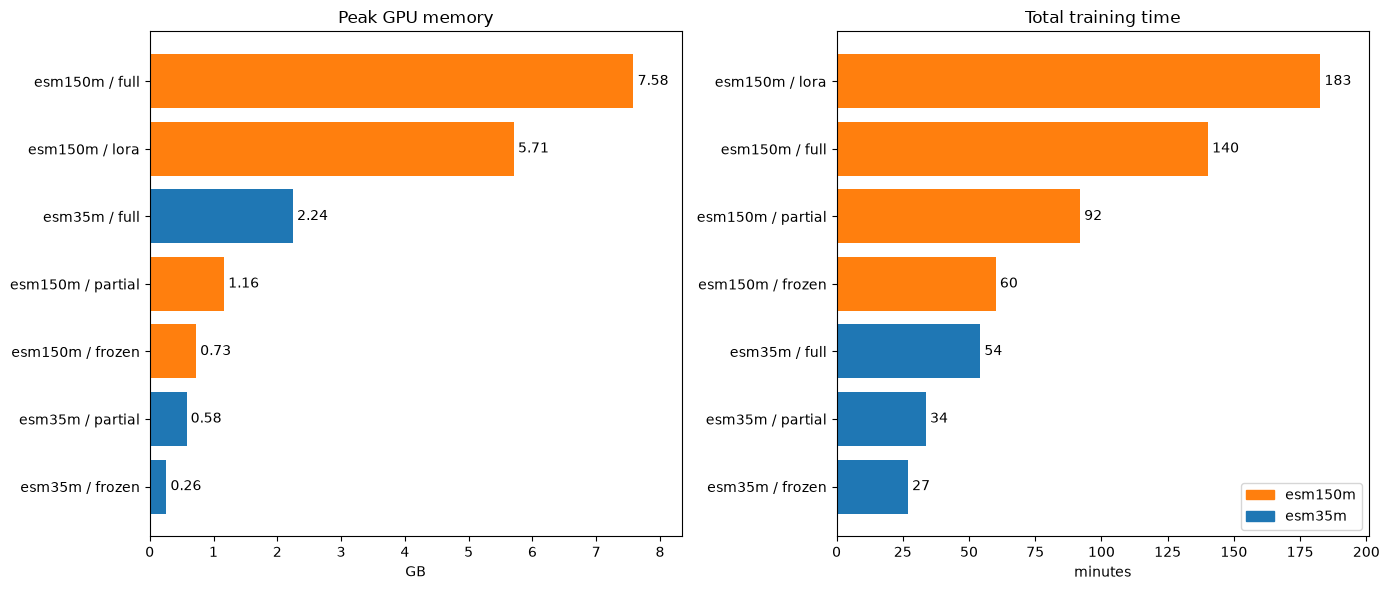

In [40]:
stats = df.groupby(['model', 'mode']).agg(
    peak_gpu_gb=('peak_gpu_memory_gb', 'max'),
    total_seconds=('seconds', 'sum'),
)
stats.index = [f'{m} / {md}' for m, md in stats.index]

colors = {'esm150m': 'tab:orange', 'esm35m': 'tab:blue'}
color_of = lambda labels: [colors[l.split(' / ')[0]] for l in labels]

fig, ax = plt.subplots(1, 2, figsize=(14, 6))

gpu = stats['peak_gpu_gb'].sort_values()
ax[0].barh(gpu.index, gpu.values, color=color_of(gpu.index))
ax[0].set_title('Peak GPU memory')
ax[0].set_xlabel('GB')
ax[0].bar_label(ax[0].containers[0], fmt='%.2f', padding=3)

secs = stats['total_seconds'].sort_values()
ax[1].barh(secs.index, secs.values / 60, color=color_of(secs.index))
ax[1].set_title('Total training time')
ax[1].set_xlabel('minutes')
ax[1].bar_label(ax[1].containers[0], fmt='%.0f', padding=3)
ax[1].legend(handles=[Patch(color=c, label=m) for m, c in colors.items()])

ax[0].margins(x=0.1)
ax[1].margins(x=0.1)

fig.tight_layout()
plt.show()


In [44]:
rows = []

for dir in DATA.iterdir():
  model, mode = dir.name.split('_')

  with open(dir / "test_metrics.json") as f:
    rows.append({'model': model, 'mode': mode, **json.load(f)})

test_metrics = pd.DataFrame(rows)
test_metrics.head()


,model,mode,macro_f1,micro_f1,exact_match,loss
0,esm150m,frozen,0.318363,0.480062,0.147932,0.814612
1,esm35m,partial,0.322916,0.521057,0.223063,0.957539
2,esm150m,full,0.365588,0.552670,0.322656,1.054571
3,esm35m,full,0.340966,0.551544,0.274316,1.182005
4,esm150m,partial,0.355589,0.542997,0.270239,0.981357


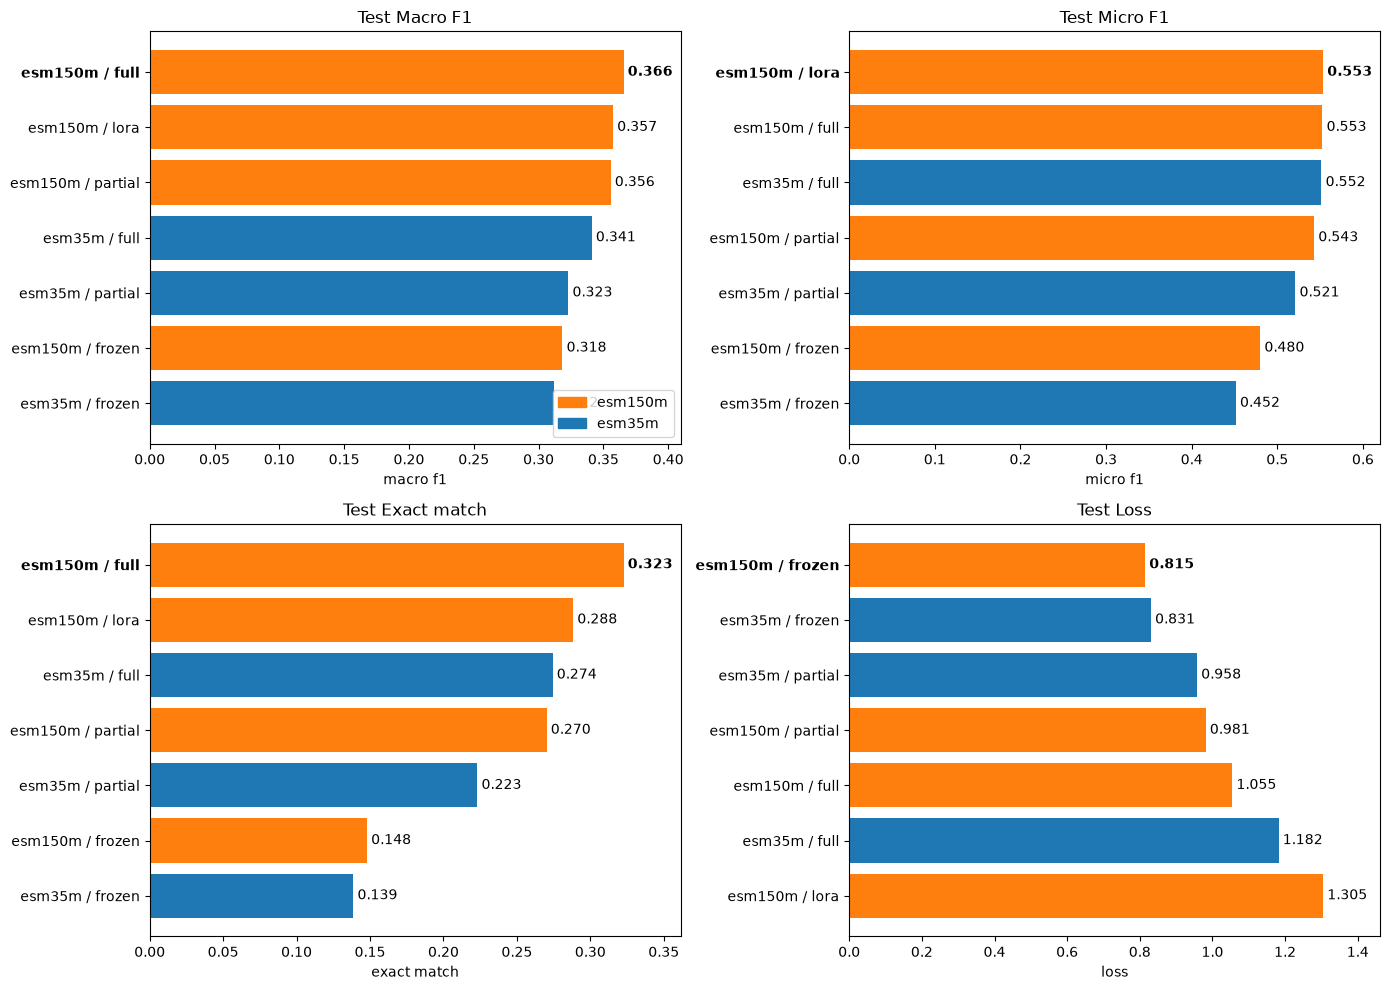

In [ ]:
tm = test_metrics.set_index(test_metrics['model'] + ' / ' + test_metrics['mode'])

panels = [
  ('macro_f1', 'Macro F1', False),
  ('micro_f1', 'Micro F1', False),
  ('exact_match', 'Exact match', False),
  ('loss', 'Loss', True),  # lower is better -> best on top
]

fig, ax = plt.subplots(2, 2, figsize=(14, 10))

for a, (col, title, descending) in zip(ax.flat, panels):
  values = tm[col].sort_values(ascending=not descending)
  a.barh(values.index, values.values, color=color_of(values.index))
  a.set_title(f'Test {title}')
  a.set_xlabel(title.lower())
  labels = a.bar_label(a.containers[0], fmt='%.3f', padding=3)
  a.margins(x=0.12)

  labels[-1].set_fontweight('bold')
  a.get_yticklabels()[-1].set_fontweight('bold')

ax[0][0].legend(
  handles=[Patch(color=c, label=m) for m, c in colors.items()],
  loc='lower right'
)

fig.tight_layout()
plt.show()

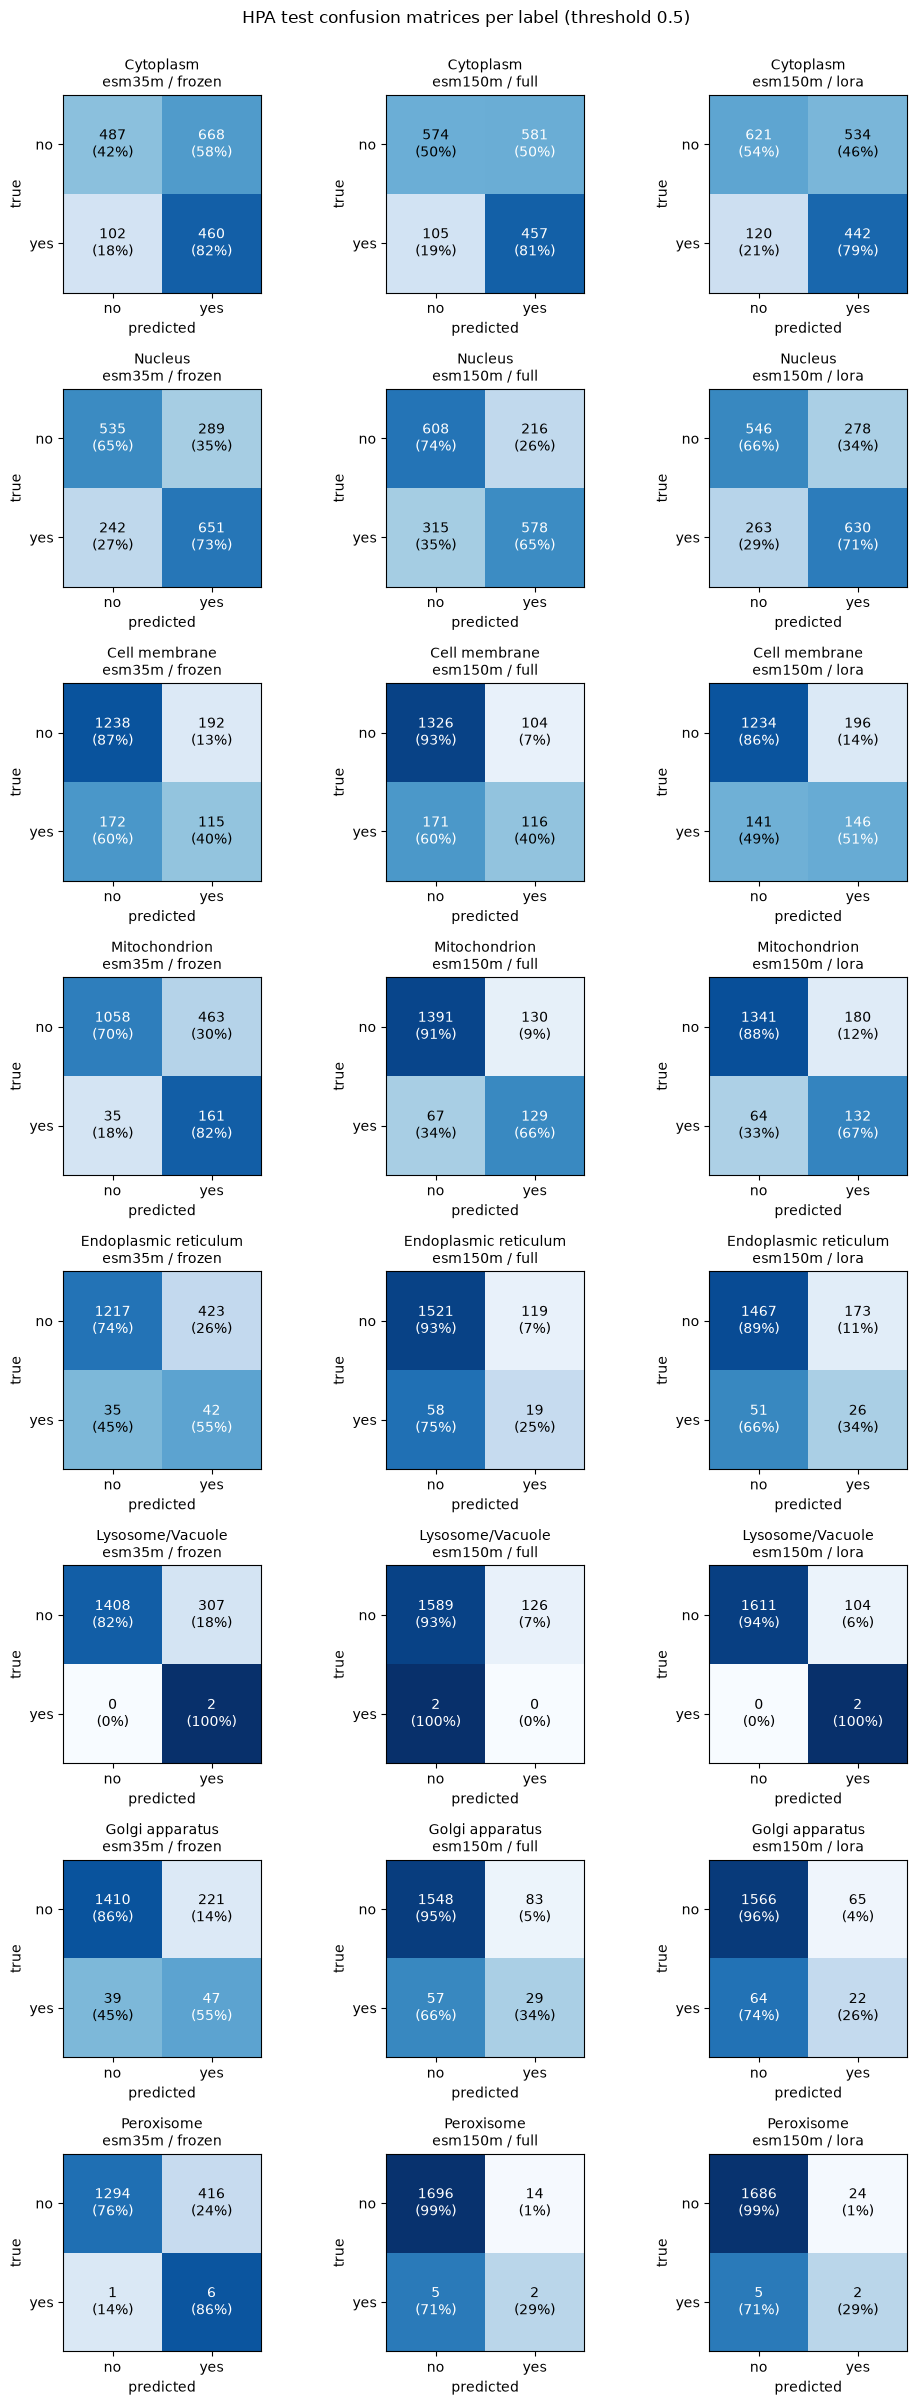

In [48]:
runs = [('esm35m', 'frozen'), ('esm150m', 'full'), ('esm150m', 'lora')]
label_names = json.load(open(DATA / 'esm35m_frozen' / 'labels.json'))
preds = {run: pd.read_csv(DATA / f'{run[0]}_{run[1]}' / 'test_predictions.csv') for run in runs}

fig, ax = plt.subplots(len(label_names), len(runs), figsize=(10, 3 * len(label_names)))

for j, run in enumerate(runs):
  p = preds[run]
  for i, label in enumerate(label_names):
    a = ax[i][j]
    cm = pd.crosstab(p[f'true_{label}'], p[f'pred_{label}']).reindex(index=[0, 1], columns=[0, 1], fill_value=0).values
    cm_norm = cm / cm.sum(axis=1, keepdims=True)  # color = share of each true row

    a.imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)
    for r in range(2):
      for c in range(2):
        a.text(c, r, f'{cm[r, c]}\n({cm_norm[r, c]:.0%})', ha='center', va='center',
               color='white' if cm_norm[r, c] > 0.5 else 'black')

    a.set_xticks([0, 1], ['no', 'yes'])
    a.set_yticks([0, 1], ['no', 'yes'])
    a.set_xlabel('predicted')
    a.set_ylabel('true')
    a.set_title(f'{label}\n{run[0]} / {run[1]}', fontsize=10)

fig.suptitle('HPA test confusion matrices per label (threshold 0.5)', y=1.0)
fig.tight_layout()
plt.show()